# Merchant descriptors: Is embedding similarity a reliable factor?
### An evaluation of EmbeddingGemma 2 on real card-transaction descriptors proving its blind_spot

The following notebook measures how a general-purpose embedding model (`google/embeddinggemma-2`) behaves
when it is used to match **raw card-transaction merchant descriptors** (e.g. `AMZN MKTP US*Z58J27N20`,
`SQ *SHAKE SHACK`, `WAL-MART #2791`) against a reference set of previously seen descriptors.

**What is measured** (it reports numbers and plots only; it draws no conclusions):

| Section | Measurement | Hypothesis it addresses |
|---|---|---|
| 8a | Top-1 accuracy by how often the merchant was seen before (0 / 1 / 2–5 / 6+) | H1 (step at zero prior occurrences) |
| 8b–8e | Similarity of correct vs wrong matches, trust-threshold sweep, reliability bins, novelty AUROC | H2 (similarity vs correctness) |
| 9 | Highest-similarity matches to a *different* merchant | H3 (lookalike "false friends") |
| 10 | Retrieval under realistic descriptor corruptions | H4 (descriptor noise) |
| 6, 8a | Character n-gram TF-IDF nearest neighbour with the same metrics | H5 (lexical baseline) |
| 11 | Task-prompt comparison (documented prompts vs none vs STS) | robustness of the setup |

**How to run (Colab free tier):** *Runtime → Change runtime type → T4 GPU*, then *Run all*.
The configuration cell (section 1) holds every setting. Each stage prints its wall-clock time.

**Outputs:** `results/` (CSV tables, `metrics.json`, `figures/`, README table snippets) and `data/`
(the exact evaluation data used). Section 14 zips them for download.

## 0. Install pinned dependencies

In [1]:

%pip install -q "sentence-transformers==6.1.0" "transformers==5.20.1" "huggingface_hub==1.33.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 92.7 MB/s eta 0:00:00


## 1. Configuration
Every setting lives here. Leave `SPLIT_DATE = None` on the first run. The notebook prints the
computed date, which you should then paste here to freeze it.

In [2]:
import os

# ---------------- Model ----------------
MODEL_ID = "google/embeddinggemma-2"
MODEL_REVISION = "914f7f89142e33e77833254d9c9b90c3cef7303b"  # pinned Hub commit
DTYPE = "float32"            # the model card says not to use float16; the T4 has no native bf16
MAX_SEQ_LENGTH = 128         # descriptors are short; a check below asserts nothing is truncated
QUERY_PROMPT_NAME = "query"     # model.prompts["query"]    == "task: search result | query: "
DOC_PROMPT_NAME = "document"    # model.prompts["document"] == "title: none | text: "
RUN_PROMPT_ABLATION = True
PROMPT_ABLATION = {             # name -> (query prompt_name, document prompt_name); None = no prompt
    "no_prompt": (None, None),
    "sts_both_sides": ("STS", "STS"),
}
ENC_BATCH = 256              # encoding batch size
SIM_CHUNK = 1024             # query rows per similarity matmul chunk

# ---------------- Data ----------------
# State of Delaware "State Employee Credit Card Transactions" (https://data.delaware.gov/d/nurt-5rqw)
# For an exact re-run from the published snapshot, set DATA_URL to
#   "hf://buckets/<owner>/<bucket>/data/transactions_window.csv.gz"
# and EXPECTED_DATA_SHA256 to the "data.sha256" value in the published metrics.json.
DATA_URL = "https://data.delaware.gov/api/views/nurt-5rqw/rows.csv?accessType=DOWNLOAD"
EXPECTED_DATA_SHA256 = None
DATA_SOURCE_PAGE = "https://data.delaware.gov/d/nurt-5rqw"
DATA_LICENSE = "Public Domain (State of Delaware Open Data; attribution: Department of Finance, Division of Accounting)"
LICENSE_ALLOWS_REDISTRIBUTION = True
COLUMN_MAP = {"TRANS_DT": "date", "MERCHANT": "descriptor", "CAT_DESCR": "category"}  # source -> canonical
DATE_FORMAT = "%m/%d/%Y"
DATA_START, DATA_END = "2022-07-01", "2026-06-30"   # fixed window (Delaware fiscal years 2023-2026)
EXCLUDE_CATEGORIES = ["internal transaction"]        # after category normalisation (chargebacks etc.)

# Merchant-key rule (the dataset has no merchant id; see section 3)
PROCESSOR_PREFIXES = ["SQ", "TST", "PAYPAL", "PP", "SP", "IN", "PY", "WPY", "TOAST", "GOOGLE",   # stripped before '*'
                      "APLPAY", "SUMUP", "IZ", "ZTL", "CKE", "FS", "BT", "EB", "DD", "PMT"]      # e.g. 'SQ *SHAKE SHACK'
SPACE_PREFIXES = ["SP", "EB", "DD"]   # processor prefixes that also appear without '*', e.g. 'SP VIKTOS' (Shopify)
KEY_STOPWORDS = ["INC", "LLC", "CO", "CORP", "LTD", "COM", "THE", "AND"]

# ---------------- Split and sampling ----------------
SPLIT_DATE = None            # e.g. "2025-09-04". None: computed from SPLIT_QUANTILE (then freeze it here)
SPLIT_QUANTILE = 0.8
N_QUERIES = 20000
SEED = 42
BUCKETS = [("0", 0, 0), ("1", 1, 1), ("2-5", 2, 5), ("6+", 6, None)]  # prior occurrences (label, min, max)

# ---------------- Metrics ----------------
N_BOOTSTRAP = 1000
THRESHOLDS = [round(0.30 + 0.01 * i, 2) for i in range(71)]   # 0.30 ... 1.00
README_THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]            # rows shown in the README table
RELIABILITY_BIN_WIDTH = 0.05
N_LOOKALIKES = 50
N_FAILURES_PER_BUCKET = 10

# ---------------- Noise robustness ----------------
N_NOISE = 1000
TRUNC_LEN = 12
NOISE_PREFIXES = ["SQ *", "TST* ", "PAYPAL *"]

# ---------------- Lexical baseline ----------------
LEX_ANALYZER = "char_wb"
LEX_NGRAM = (3, 5)
LEX_CHUNK = 512

# ---------------- Output ----------------
RESULTS_DIR = "results"
DATA_OUT_DIR = "data"
CACHE_DIR = "cache"          # raw download and embedding caches (not published)

# ---------------- Smoke test (pipeline check only: its numbers are NOT results) ----------------
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"
SMOKE_MAX_REF = None
if SMOKE_TEST:
    N_QUERIES, N_NOISE, N_BOOTSTRAP, ENC_BATCH, SMOKE_MAX_REF = 300, 60, 50, 64, 3000
    RESULTS_DIR, DATA_OUT_DIR = "results_smoke", "data_smoke"
    print("SMOKE TEST MODE: tiny sizes; outputs go to", RESULTS_DIR)

## 2. Imports, seeds, environment

In [3]:
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # must be set before CUDA initialises

import gzip, hashlib, json, platform, random, re, shutil, sys, time, urllib.request, zipfile
from contextlib import contextmanager
from importlib.metadata import version as pkg_version

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score
import sentence_transformers
from sentence_transformers import SentenceTransformer

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
ENV = {
    "python": sys.version.split()[0], "platform": platform.platform(), "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    **{p: pkg_version(p) for p in ["torch", "torchvision", "transformers", "sentence-transformers",
                                   "huggingface_hub", "scikit-learn", "pandas", "numpy", "matplotlib"]},
}
for d in (RESULTS_DIR, f"{RESULTS_DIR}/figures", f"{RESULTS_DIR}/readme_auto", DATA_OUT_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)
print(json.dumps(ENV, indent=2))
if DEVICE != "cuda":
    print("WARNING: no CUDA GPU detected. The full run is intended for a Colab T4.")

{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "device": "cuda",
  "gpu": "Tesla T4",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "transformers": "5.20.1",
  "sentence-transformers": "6.1.0",
  "huggingface_hub": "1.33.0",
  "scikit-learn": "1.6.1",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "matplotlib": "3.10.0"
}


In [4]:
# ---- Small helpers used throughout ----
TIMINGS = {}

@contextmanager
def timed(name):
    t0 = time.time()
    yield
    TIMINGS[name] = round(time.time() - t0, 1)
    print(f"[time] {name}: {TIMINGS[name]} s")

BUCKET_LABELS = [b[0] for b in BUCKETS]

def assign_bucket(count):
    for label, lo, hi in BUCKETS:
        if count >= lo and (hi is None or count <= hi):
            return label
    raise ValueError(count)

def boot_mean_ci(x, seed=SEED):
    # Percentile bootstrap 95% CI of a mean (x is 0/1 or real-valued).
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = np.empty(N_BOOTSTRAP)
    step = max(1, int(2e7 // len(x)))       # bound memory of the resample matrix
    for s in range(0, N_BOOTSTRAP, step):
        b = min(step, N_BOOTSTRAP - s)
        means[s:s + b] = x[rng.integers(0, len(x), size=(b, len(x)))].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(lo), float(hi)

def auc_with_ci(y, score, seed=SEED):
    # ROC AUC with a percentile bootstrap 95% CI; NaN if only one class is present.
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)
    if len(y) == 0 or y.min() == y.max():
        return np.nan, (np.nan, np.nan)
    auc = roc_auc_score(y, score)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(N_BOOTSTRAP):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            vals.append(roc_auc_score(y[i], score[i]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(auc), (float(lo), float(hi))

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return float(centre - half), float(centre + half)

def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, (pd.Timestamp,)):
        return o.strftime("%Y-%m-%d")
    return o

def fmt(v, nd=3):
    return "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else f"{v:.{nd}f}"

def fmt_ci(v, lo, hi, nd=3):
    return "n/a" if v is None or np.isnan(v) else f"{v:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

def md_table(df):
    # Minimal markdown table renderer (avoids a tabulate dependency).
    cols = [str(c) for c in df.columns]
    esc = lambda s: str(s).replace("|", "\\|").replace("\n", " ")
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(esc(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)

## 3. Data: download, clean, derive merchant keys

**Source:** State of Delaware, *State Employee Credit Card Transactions*. These are real card transactions
with raw merchant descriptors and the merchant category the merchant registers with the card network.
The licence is Public Domain.

The dataset has **no merchant identifier**, so merchant identity is derived from the descriptor with
the deterministic rule `merchant_key()` below. Category correctness does not depend on this rule.
Same-merchant metrics do. A *loose* key (the first token of the strict key) is used as a sensitivity
check in section 8a.

In [5]:
_PROC_RE = re.compile(r"^(?:%s)\s*\*\s*" % "|".join(map(re.escape, PROCESSOR_PREFIXES)))
_SPACE_RE = re.compile(r"^(?:%s)\s+(?=\S)" % "|".join(map(re.escape, SPACE_PREFIXES)))
_CODE_RE = re.compile(r"#|\d{3,}")      # start of a store / order / phone number
_STOP_RE = re.compile(r"\b(?:%s)\b" % "|".join(map(re.escape, KEY_STOPWORDS)))

def _clean(s):
    # Drop punctuation ('WAL-MART' -> 'WALMART') and corporate stopwords; collapse whitespace.
    return " ".join(_STOP_RE.sub(" ", re.sub(r"[^A-Z0-9 ]", "", s)).split())

def _n_letters(s):
    return sum(c.isalpha() for c in s)

def merchant_key_with_flag(descriptor):
    # Returns (key, used_fallback).
    s = descriptor.upper().strip()
    s = _PROC_RE.sub("", s)                   # 1. 'SQ *SHAKE SHACK' -> 'SHAKE SHACK'
    s = _SPACE_RE.sub("", s)                  # 2. 'SP VIKTOS' -> 'VIKTOS'
    s = s.split("*", 1)[0]                    # 3. 'AMZN MKTP US*Z58J27N20' -> 'AMZN MKTP US'
    base = s
    s = _CODE_RE.split(s, maxsplit=1)[0]      # 4. cut at the first '#' or 3+ digit run:
                                              #    'WAL-MART #2791' -> 'WAL-MART', 'STAPLS0239279988000001' -> 'STAPLS'
    key = _clean(s)                           # 5. punctuation and stopwords
    toks = key.split()
    if len(toks) > 1 and len(toks[-1]) == 1 and toks[-1].isalpha():
        key = " ".join(toks[:-1])             # 6. drop a trailing 1-letter fragment: 'TARGET T-1312' -> 'TARGET'
    if _n_letters(key) >= 2:
        return key, False
    # 7. fallback when too little is left (e.g. '92550 - BWI DAILY GARAGE'): non-numeric tokens of step-3 text
    fb = _clean(" ".join(t for t in re.sub(r"[^A-Z0-9]+", " ", base).split() if not t.isdigit()))
    if _n_letters(fb) >= 2:
        return fb, True
    return " ".join(re.sub(r"[^A-Z0-9]+", " ", descriptor.upper()).split()), True

def merchant_key(descriptor):
    return merchant_key_with_flag(descriptor)[0]

def loose_key(key):
    return key.split()[0] if key else key

def normalise_category(c):
    return " ".join(re.sub(r"[^a-z0-9]+", " ", str(c).lower()).split())

for example in ["AMZN MKTP US*Z58J27N20", "AMAZON MKTPL*TM6N527P3", "SQ *SHAKE SHACK", "SP VIKTOS",
                "WAL-MART #2791", "STAPLES 00103010", "STAPLS0239279988000001", "PANERA BREAD #203962 O",
                "TARGET T-1312", "LOWES #02258*", "UBER *TRIP", "THE HOME DEPOT #8440", "92550 - BWI DAILY GARAGE"]:
    k = merchant_key(example)
    print(f"{example:28s} -> strict: {k:18s} loose: {loose_key(k)}")

AMZN MKTP US*Z58J27N20       -> strict: AMZN MKTP US       loose: AMZN
AMAZON MKTPL*TM6N527P3       -> strict: AMAZON MKTPL       loose: AMAZON
SQ *SHAKE SHACK              -> strict: SHAKE SHACK        loose: SHAKE
SP VIKTOS                    -> strict: VIKTOS             loose: VIKTOS
WAL-MART #2791               -> strict: WALMART            loose: WALMART
STAPLES 00103010             -> strict: STAPLES            loose: STAPLES
STAPLS0239279988000001       -> strict: STAPLS             loose: STAPLS
PANERA BREAD #203962 O       -> strict: PANERA BREAD       loose: PANERA
TARGET T-1312                -> strict: TARGET             loose: TARGET
LOWES #02258*                -> strict: LOWES              loose: LOWES
UBER *TRIP                   -> strict: UBER               loose: UBER
THE HOME DEPOT #8440         -> strict: HOME DEPOT         loose: HOME
92550 - BWI DAILY GARAGE     -> strict: BWI DAILY GARAGE   loose: BWI


In [6]:
def download_if_needed(url):
    name = os.path.basename(url.split("?")[0]) or "download"
    dest = os.path.join(CACHE_DIR, hashlib.sha1(url.encode()).hexdigest()[:10] + "_" + name)
    if os.path.exists(dest):
        print("Using cached download:", dest)
        return dest
    print("Downloading", url)
    try:  # use certifi's CA bundle when available (some local Python builds lack system certificates)
        import certifi, ssl
        ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ctx = None
    with urllib.request.urlopen(url, context=ctx) as r, open(dest + ".part", "wb") as f:
        shutil.copyfileobj(r, f, length=1 << 20)
    os.replace(dest + ".part", dest)
    print(f"Saved {os.path.getsize(dest) / 1e6:.1f} MB -> {dest}")
    return dest

def snapshot_frame(frame):
    out = frame[["date", "descriptor", "category", "merchant_key", "merchant_key_loose"]].copy()
    out["date"] = out["date"].dt.strftime("%Y-%m-%d")
    return out

def content_sha256(frame):
    # Hash of the canonical uncompressed CSV, so it does not depend on gzip headers.
    return hashlib.sha256(snapshot_frame(frame).to_csv(index=False, lineterminator="\n").encode("utf-8")).hexdigest()

with timed("load_and_clean"):
    src = download_if_needed(DATA_URL) if DATA_URL.startswith(("http://", "https://")) else DATA_URL
    header = pd.read_csv(src, nrows=0).columns.tolist()
    IS_SNAPSHOT = "merchant_key" in header
    CLEANING_LOG = {}
    if IS_SNAPSHOT:
        df = pd.read_csv(src, dtype=str, keep_default_na=False)
        df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d")
        CLEANING_LOG["snapshot_rows"] = len(df)
        key_map = {d: merchant_key(d) for d in df["descriptor"].unique()}
        assert (df["descriptor"].map(key_map) == df["merchant_key"]).all(), "merchant_key rule differs from snapshot"
    else:
        raw = pd.read_csv(src, usecols=list(COLUMN_MAP), dtype=str, keep_default_na=False)
        CLEANING_LOG["source_rows"] = len(raw)
        df = raw.rename(columns=COLUMN_MAP)[["date", "descriptor", "category"]].copy()
        del raw
        df["date"] = pd.to_datetime(df["date"], format=DATE_FORMAT, errors="coerce")
        CLEANING_LOG["unparseable_dates_dropped"] = int(df["date"].isna().sum())
        df = df.dropna(subset=["date"])
        df = df[(df["date"] >= DATA_START) & (df["date"] <= DATA_END)]
        CLEANING_LOG["rows_in_window"] = len(df)
        df["descriptor"] = df["descriptor"].str.strip()
        CLEANING_LOG["empty_descriptor_dropped"] = int((df["descriptor"] == "").sum())
        df = df[df["descriptor"] != ""]
        df["category"] = df["category"].map(normalise_category)
        bad_cat = df["category"].isin(EXCLUDE_CATEGORIES) | (df["category"] == "")
        CLEANING_LOG["excluded_or_empty_category_dropped"] = int(bad_cat.sum())
        df = df[~bad_cat]
        key_map = {d: merchant_key(d) for d in df["descriptor"].unique()}
        df["merchant_key"] = df["descriptor"].map(key_map)
        df["merchant_key_loose"] = df["merchant_key"].map(loose_key)
    df = df.sort_values(["date", "descriptor", "category"], kind="mergesort").reset_index(drop=True)
    CLEANING_LOG["final_rows"] = len(df)

DATA_SHA256 = content_sha256(df)
if EXPECTED_DATA_SHA256:
    assert DATA_SHA256 == EXPECTED_DATA_SHA256, f"data hash mismatch: {DATA_SHA256}"
print(json.dumps(CLEANING_LOG, indent=2))
print("date range:", df["date"].min().date(), "->", df["date"].max().date())
print("distinct descriptors:", df["descriptor"].nunique(), "| categories:", df["category"].nunique(),
      "| strict keys:", df["merchant_key"].nunique(), "| loose keys:", df["merchant_key_loose"].nunique())
print("content SHA-256:", DATA_SHA256)

Saved 276.9 MB -> cache/7e2b2c7e01_rows.csv
[time] load_and_clean: 570.1 s
{
  "source_rows": 2251316,
  "unparseable_dates_dropped": 0,
  "rows_in_window": 766650,
  "empty_descriptor_dropped": 0,
  "excluded_or_empty_category_dropped": 4144,
  "final_rows": 762506
}
date range: 2022-07-01 -> 2026-06-30
distinct descriptors: 189235 | categories: 250 | strict keys: 45396 | loose keys: 21491
content SHA-256: af512487ebf6bc2c1fee924ee5bace690a8cbffe61d1d09ddd098b9825d26f70


In [7]:
# ---- Merchant-key diagnostics (audit the derived identity) ----
uniq = pd.Series(df["descriptor"].unique())
fallback_used = uniq[[merchant_key_with_flag(d)[1] for d in uniq]]
n_fallback = int(len(fallback_used))
print("fallback examples:", [(d, merchant_key(d)) for d in fallback_used.head(8)])
key_stats = (df.groupby("merchant_key")
               .agg(n_transactions=("descriptor", "size"), n_descriptor_variants=("descriptor", "nunique"))
               .sort_values("n_transactions", ascending=False))
majority_share = df.groupby("merchant_key")["category"].agg(lambda c: c.value_counts().iloc[0]).sum() / len(df)
majority_share_desc = df.groupby("descriptor")["category"].agg(lambda c: c.value_counts().iloc[0]).sum() / len(df)
top_variants = (df.groupby(["merchant_key", "descriptor"]).size().rename("n").reset_index()
                  .sort_values(["merchant_key", "n", "descriptor"], ascending=[True, False, True])
                  .groupby("merchant_key")["descriptor"].apply(lambda s: " || ".join(s.head(5))))
key_diag = key_stats.join(top_variants.rename("top_variants")).head(200).reset_index()
key_diag.to_csv(f"{RESULTS_DIR}/merchant_key_diagnostics.csv", index=False)
KEY_DIAGNOSTICS = {
    "n_strict_keys": int(df["merchant_key"].nunique()), "n_loose_keys": int(df["merchant_key_loose"].nunique()),
    "n_distinct_descriptors": int(len(uniq)), "n_descriptors_using_fallback_key": n_fallback,
    "category_majority_share_per_strict_key": float(majority_share),
    "category_majority_share_per_descriptor": float(majority_share_desc),
}
print(json.dumps(KEY_DIAGNOSTICS, indent=2))
pd.set_option("display.max_colwidth", 120)
display(key_diag.head(15))
rng_ex = np.random.default_rng(SEED)
display(pd.DataFrame({"descriptor": uniq.iloc[rng_ex.choice(len(uniq), 15, replace=False)].values})
          .assign(strict_key=lambda d: d["descriptor"].map(merchant_key),
                  loose_key=lambda d: d["strict_key"].map(loose_key)))

fallback examples: [('92550 - BWI DAILY GARAGE', 'BWI DAILY GARAGE'), ('EB 2022 DNLA SUMMER T', 'DNLA SUMMER T'), ('92552 - BWI LONG TERM A', 'BWI LONG TERM A'), ('D J*WALL-ST-JOURNAL', 'D J'), ('1000BULBS.COM', '1000BULBS'), ('SQ *302 YARD SIGNS', 'YARD SIGNS'), ('365 MARKET 888 432-3299', 'MARKET'), ('618 HILTON BATON ROUGE', 'HILTON BATON ROUGE')]
{
  "n_strict_keys": 45396,
  "n_loose_keys": 21491,
  "n_distinct_descriptors": 189235,
  "n_descriptors_using_fallback_key": 657,
  "category_majority_share_per_strict_key": 0.966196987302395,
  "category_majority_share_per_descriptor": 0.9821785008904848
}


,merchant_key,n_transactions,n_descriptor_variants,top_variants
0,AMZN MKTP US,39012,35064,AMZN MKTP US || AMZN MKTP US*T17Y65AQ1 || AMZN MKTP US*TO2KV00Y0 || AMZN MKTP US*TO40B6B11 || AMZN MKTP US*TO8G91PP0
1,AMAZON MKTPL,33831,31669,AMAZON MKTPL || AMAZON MKTPL*J60O66AZ3 || AMAZON MKTPL*TM6N527P3 || AMAZON MKTPL*ZX5W44N92 || AMAZON MKTPL*PE2S19TR3
2,STAPLS,18035,15096,STAPLS0209978943000001 || STAPLS0209893059000001 || STAPLS0216657797000001 || STAPLS0211405616000001 || STAPLS022758...
3,AMAZONCOM,17752,16412,AMAZON.COM || AMAZON.COM*H59SP4BW2 || AMAZON.COM*H54093BF2 || AMAZON.COM*H57PD4B02 || AMAZON.COM*H578X3BW2
4,GRAINGER,17196,1,GRAINGER
5,LOWES,12351,23,LOWES #00907* || LOWES #00587* || LOWES #02795* || LOWES #02537* || LOWES #02258*
6,VERIZONWRLSS,11539,2,VERIZONWRLSS*RTCCR VB || VERIZONWRLSS
7,AMERICAN AIR,11234,10297,AMERICAN AIR || AMERICAN AIR0010638423505 || AMERICAN AIR0012491080763 || AMERICAN AIR0010262642430 || AMERICAN AIR0...
8,WALMARTCOM,9800,3,WALMART.COM || WALMART.COM 8009256278 || WALMART.COM 8009666546
9,EASTERN SHORE COFFEE WA,7454,1,EASTERN SHORE COFFEE And WA


,descriptor,strict_key,loose_key
0,AMAZON.COM*148J79E52,AMAZONCOM,AMAZONCOM
1,GO EXPRESS TRAVEL,GO EXPRESS TRAVEL,GO
2,AMERICAN AI 0012198118505,AMERICAN AI,AMERICAN
3,AMAZON.COM*N692U4Q70,AMAZONCOM,AMAZONCOM
4,AMAZON.COM*HG9UY8IT0,AMAZONCOM,AMAZONCOM
5,LUPI S ISLA VERDE,LUPI S ISLA VERDE,LUPI
6,NUMOTION,NUMOTION,NUMOTION
7,AMAZON MKTPL*NI1WC6TS2,AMAZON MKTPL,AMAZON
8,FEDEX775193657286,FEDEX,FEDEX
9,SWA*EXCSBAG5264297848696,SWA,SWA


## 4. Temporal split, query sample, prior-occurrence buckets
Reference set: transactions **before** `SPLIT_DATE`. Queries: a seeded uniform sample of transactions
**on or after** it. *Prior occurrences* means the number of reference **transactions** with the same
merchant key. Reference descriptors are deduplicated by exact string. Each one keeps its majority
category, with ties broken alphabetically.

In [8]:
with timed("split"):
    if SPLIT_DATE is None:
        split_date = df["date"].quantile(SPLIT_QUANTILE).normalize()
        SPLIT_COMPUTED = True
        print(f'>>> Computed split date at quantile {SPLIT_QUANTILE}: {split_date.date()}')
        print(f'>>> Freeze it: set SPLIT_DATE = "{split_date.date()}" in the configuration cell.')
    else:
        split_date = pd.Timestamp(SPLIT_DATE)
        SPLIT_COMPUTED = False

    ref_txn = df[df["date"] < split_date]
    pool = df[df["date"] >= split_date]
    assert ref_txn["date"].max() < split_date <= pool["date"].min()

    rng = np.random.default_rng(SEED)
    q_idx = np.sort(rng.choice(len(pool), size=min(N_QUERIES, len(pool)), replace=False))
    queries = pool.iloc[q_idx].reset_index(drop=True).copy()

    ref_counts = ref_txn["merchant_key"].value_counts()
    ref_counts_loose = ref_txn["merchant_key_loose"].value_counts()
    queries["prior_count"] = queries["merchant_key"].map(ref_counts).fillna(0).astype(int)
    queries["prior_count_loose"] = queries["merchant_key_loose"].map(ref_counts_loose).fillna(0).astype(int)
    queries["bucket"] = queries["prior_count"].map(assign_bucket)
    queries["bucket_loose"] = queries["prior_count_loose"].map(assign_bucket)

    # Deduplicate reference descriptors: majority category per exact descriptor string.
    g = ref_txn.groupby(["descriptor", "category"]).size().rename("n").reset_index()
    n_label_conflicts = int((g.groupby("descriptor").size() > 1).sum())
    g = g.sort_values(["descriptor", "n", "category"], ascending=[True, False, True], kind="mergesort")
    ref_desc = g.drop_duplicates("descriptor", keep="first").drop(columns="n")
    ref_desc = ref_desc.merge(g.groupby("descriptor")["n"].sum().rename("n_transactions").reset_index(), on="descriptor")
    ref_desc["merchant_key"] = ref_desc["descriptor"].map(merchant_key)
    ref_desc["merchant_key_loose"] = ref_desc["merchant_key"].map(loose_key)
    ref_desc = ref_desc.sort_values("descriptor", kind="mergesort").reset_index(drop=True)
    if SMOKE_MAX_REF:
        keep = np.sort(np.random.default_rng(SEED).choice(len(ref_desc), size=min(SMOKE_MAX_REF, len(ref_desc)), replace=False))
        ref_desc = ref_desc.iloc[keep].reset_index(drop=True)

bucket_counts = queries["bucket"].value_counts().reindex(BUCKET_LABELS, fill_value=0)
bucket_counts_loose = queries["bucket_loose"].value_counts().reindex(BUCKET_LABELS, fill_value=0)
assert bucket_counts.sum() == len(queries) == bucket_counts_loose.sum()
SPLIT_INFO = {
    "split_date": split_date.strftime("%Y-%m-%d"), "computed_from_quantile": SPLIT_COMPUTED, "quantile": SPLIT_QUANTILE,
    "reference_date_range": [ref_txn["date"].min().strftime("%Y-%m-%d"), ref_txn["date"].max().strftime("%Y-%m-%d")],
    "query_pool_date_range": [pool["date"].min().strftime("%Y-%m-%d"), pool["date"].max().strftime("%Y-%m-%d")],
    "n_reference_transactions": len(ref_txn), "n_reference_descriptors": len(ref_desc),
    "n_reference_descriptors_with_label_conflicts": n_label_conflicts,
    "n_query_pool": len(pool), "n_queries": len(queries),
    "bucket_counts_strict": bucket_counts.to_dict(), "bucket_counts_loose": bucket_counts_loose.to_dict(),
}
print(json.dumps(SPLIT_INFO, indent=2))
display(pd.DataFrame({"strict": bucket_counts, "strict_share": (bucket_counts / len(queries)).round(4),
                      "loose": bucket_counts_loose, "loose_share": (bucket_counts_loose / len(queries)).round(4)}))

>>> Computed split date at quantile 0.8: 2025-09-04
>>> Freeze it: set SPLIT_DATE = "2025-09-04" in the configuration cell.
[time] split: 1.9 s
{
  "split_date": "2025-09-04",
  "computed_from_quantile": true,
  "quantile": 0.8,
  "reference_date_range": [
    "2022-07-01",
    "2025-09-03"
  ],
  "query_pool_date_range": [
    "2025-09-04",
    "2026-06-30"
  ],
  "n_reference_transactions": 609394,
  "n_reference_descriptors": 154361,
  "n_reference_descriptors_with_label_conflicts": 1123,
  "n_query_pool": 153112,
  "n_queries": 20000,
  "bucket_counts_strict": {
    "0": 1960,
    "1": 335,
    "2-5": 848,
    "6+": 16857
  },
  "bucket_counts_loose": {
    "0": 709,
    "1": 208,
    "2-5": 541,
    "6+": 18542
  }
}


,strict,strict_share,loose,loose_share
0,1960,0.0980,709,0.0354
1,335,0.0168,208,0.0104
2-5,848,0.0424,541,0.0270
6+,16857,0.8428,18542,0.9271


In [9]:
# ---- Save the exact evaluation data (public domain, so redistributable) ----
if LICENSE_ALLOWS_REDISTRIBUTION:
    def write_csv_gz(frame, path):
        with open(path, "wb") as fh, gzip.GzipFile(filename="", mode="wb", fileobj=fh, mtime=0) as gz:
            gz.write(frame.to_csv(index=False, lineterminator="\n").encode("utf-8"))
    write_csv_gz(snapshot_frame(df), f"{DATA_OUT_DIR}/transactions_window.csv.gz")
    write_csv_gz(ref_desc, f"{DATA_OUT_DIR}/reference_descriptors.csv.gz")
    q_out = queries.copy()
    q_out["date"] = q_out["date"].dt.strftime("%Y-%m-%d")
    write_csv_gz(q_out, f"{DATA_OUT_DIR}/queries.csv.gz")
    print("Saved:", sorted(os.listdir(DATA_OUT_DIR)))
else:
    print("Licence does not allow redistribution: data files not written (hash recorded in metrics.json).")

Saved: ['queries.csv.gz', 'reference_descriptors.csv.gz', 'transactions_window.csv.gz']


## 5. Model and embeddings
The full published checkpoint is loaded (text, vision and audio towers) in float32. Text inputs pass
only through the text encoder. Queries use the documented `query` prompt and reference descriptors use
the `document` prompt. Embeddings are L2-normalised, so the dot product is cosine similarity.

In [10]:
assert DTYPE != "float16", "EmbeddingGemma 2 must not run in float16 (model card)"
with timed("load_model"):
    model = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, device=DEVICE,
                                model_kwargs={"dtype": getattr(torch, DTYPE)})
    model.max_seq_length = MAX_SEQ_LENGTH
N_PARAMS = sum(p.numel() for p in model.parameters())
PROMPTS = {name: model.prompts[name] for name in sorted({QUERY_PROMPT_NAME, DOC_PROMPT_NAME,
           *[p for pair in PROMPT_ABLATION.values() for p in pair]} - {None})}
print(f"parameters: {N_PARAMS:,} | dtype: {next(model.parameters()).dtype} | device: {DEVICE}")
print("prompts used:", json.dumps(PROMPTS, indent=2))

def prompt_text(name):
    return "" if name is None else model.prompts[name]

# No input may be truncated: check the longest tokenised input (prompt + descriptor).
longest = max(len(ids) for ids in model.tokenizer(
    [prompt_text(DOC_PROMPT_NAME) + d for d in ref_desc["descriptor"]] +
    [prompt_text(QUERY_PROMPT_NAME) + d for d in queries["descriptor"]])["input_ids"])
print("longest tokenised input:", longest)
assert longest < MAX_SEQ_LENGTH

modules.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/1.56k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/21.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

[time] load_model: 33.0 s
parameters: 744,371,488 | dtype: torch.float32 | device: cuda
prompts used: {
  "STS": "task: sentence similarity | query: ",
  "document": "title: none | text: ",
  "query": "task: search result | query: "
}
longest tokenised input: 29


In [11]:
def encode_texts(texts, prompt_name, tag):
    # Encode with a task prompt, L2-normalise, cache to .npy (keyed by model revision, prompt and texts).
    texts = list(texts)
    h = hashlib.sha1("\x1f".join([MODEL_REVISION, DTYPE, str(prompt_name)] + texts).encode()).hexdigest()[:12]
    path = os.path.join(CACHE_DIR, f"emb_{tag}_{h}.npy")
    if os.path.exists(path):
        emb = torch.from_numpy(np.load(path)).to(DEVICE)
    else:
        emb = model.encode(texts, prompt_name=prompt_name, batch_size=ENC_BATCH, normalize_embeddings=True,
                           convert_to_tensor=True, show_progress_bar=len(texts) > 5000).float()
        np.save(path, emb.cpu().numpy())
    norms = emb.norm(dim=1)
    assert torch.allclose(norms, torch.ones_like(norms), atol=1e-3), "embeddings are not unit-norm"
    return emb

@torch.no_grad()
def topk_search(q_emb, r_emb, k=2, chunk=SIM_CHUNK):
    # Chunked exact nearest-neighbour search by cosine similarity (rows are unit-norm).
    k = min(k, r_emb.shape[0])
    idx, sim = [], []
    for s in range(0, q_emb.shape[0], chunk):
        v, i = torch.topk(q_emb[s:s + chunk] @ r_emb.T, k=k, dim=1)
        idx.append(i.cpu())
        sim.append(v.float().cpu())
    return torch.cat(idx).numpy(), torch.cat(sim).numpy()

with timed("encode_reference"):
    ref_emb = encode_texts(ref_desc["descriptor"], DOC_PROMPT_NAME, "ref_doc")
with timed("encode_queries"):
    q_emb = encode_texts(queries["descriptor"], QUERY_PROMPT_NAME, "query_query")
with timed("retrieve"):
    emb_idx, emb_sim = topk_search(q_emb, ref_emb, k=2)

# Sanity check of the index alignment: each reference vector must retrieve itself.
probe = np.random.default_rng(SEED).choice(len(ref_desc), size=min(200, len(ref_desc)), replace=False)
self_idx, _ = topk_search(ref_emb[probe], ref_emb, k=1)
self_rate = float((self_idx[:, 0] == probe).mean())
print("self-retrieval rate:", self_rate)
assert self_rate >= 0.99
print("reference matrix:", tuple(ref_emb.shape), "| queries:", tuple(q_emb.shape))

Batches:   0%|          | 0/603 [00:00<?, ?it/s]

[time] encode_reference: 413.6 s


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

[time] encode_queries: 56.2 s
[time] retrieve: 1.8 s
self-retrieval rate: 1.0
reference matrix: (154361, 768) | queries: (20000, 768)


## 6. Lexical baseline: character n-gram TF-IDF nearest neighbour
`TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), lowercase=True, sublinear_tf=True)` is fitted on the
**reference descriptors only**. Rows are L2-normalised, so the sparse dot product is cosine similarity.
A query that shares no n-gram with any reference is counted as wrong and flagged.

In [12]:
with timed("lexical"):
    LEX_VEC = TfidfVectorizer(analyzer=LEX_ANALYZER, ngram_range=LEX_NGRAM, lowercase=True,
                              sublinear_tf=True, dtype=np.float32)
    LEX_REF = LEX_VEC.fit_transform(ref_desc["descriptor"])
    LEX_REF_T = LEX_REF.T.tocsr()

    def lex_top1(texts):
        Q = LEX_VEC.transform(list(texts))
        idx = np.zeros(Q.shape[0], dtype=np.int64)
        sim = np.zeros(Q.shape[0], dtype=np.float32)
        for s in range(0, Q.shape[0], LEX_CHUNK):
            S = (Q[s:s + LEX_CHUNK] @ LEX_REF_T).tocsr()
            idx[s:s + LEX_CHUNK] = np.asarray(S.argmax(axis=1)).ravel()
            sim[s:s + LEX_CHUNK] = S.max(axis=1).toarray().ravel()
        return idx, sim, sim > 0

    lex_idx, lex_sim, lex_overlap = lex_top1(queries["descriptor"])

# Sanity check: each reference descriptor retrieves itself (case-insensitive, since lowercase=True).
p_idx, _, _ = lex_top1(ref_desc["descriptor"].iloc[probe])
lex_self = float((ref_desc["descriptor"].str.lower().values[p_idx] == ref_desc["descriptor"].str.lower().values[probe]).mean())
print("lexical vocabulary:", len(LEX_VEC.vocabulary_), "| self-retrieval rate:", lex_self,
      "| queries with no n-gram overlap:", int((~lex_overlap).sum()))
assert lex_self >= 0.99

[time] lexical: 42.7 s
lexical vocabulary: 1092330 | self-retrieval rate: 1.0 | queries with no n-gram overlap: 0


## 7. Per-query results → `query_results.csv`

In [13]:
R = ref_desc  # short alias
i1 = emb_idx[:, 0]
res = pd.DataFrame({
    "query_date": queries["date"].dt.strftime("%Y-%m-%d"),
    "query_descriptor": queries["descriptor"], "query_category": queries["category"],
    "query_merchant_key": queries["merchant_key"], "query_merchant_key_loose": queries["merchant_key_loose"],
    "prior_count": queries["prior_count"], "bucket": queries["bucket"],
    "prior_count_loose": queries["prior_count_loose"], "bucket_loose": queries["bucket_loose"],
    "exact_string_in_reference": queries["descriptor"].isin(set(R["descriptor"])),
    # embedding top-1
    "matched_descriptor": R["descriptor"].values[i1], "matched_category": R["category"].values[i1],
    "matched_merchant_key": R["merchant_key"].values[i1], "matched_merchant_key_loose": R["merchant_key_loose"].values[i1],
    "sim_top1": emb_sim[:, 0],
    "sim_top2": emb_sim[:, 1] if emb_sim.shape[1] > 1 else np.nan,
    # lexical top-1
    "lex_matched_descriptor": R["descriptor"].values[lex_idx], "lex_matched_category": R["category"].values[lex_idx],
    "lex_matched_merchant_key": R["merchant_key"].values[lex_idx], "lex_sim_top1": lex_sim, "lex_has_overlap": lex_overlap,
})
res["margin"] = res["sim_top1"] - res["sim_top2"]
res["category_correct"] = res["matched_category"] == res["query_category"]
res["same_merchant"] = res["matched_merchant_key"] == res["query_merchant_key"]
res["same_merchant_loose"] = res["matched_merchant_key_loose"] == res["query_merchant_key_loose"]
res["lex_category_correct"] = (res["lex_matched_category"] == res["query_category"]) & res["lex_has_overlap"]
res["lex_same_merchant"] = (res["lex_matched_merchant_key"] == res["query_merchant_key"]) & res["lex_has_overlap"]
res["lex_same_merchant_loose"] = (R["merchant_key_loose"].values[lex_idx] == res["query_merchant_key_loose"]) & res["lex_has_overlap"]

# By construction an unseen merchant cannot be matched to the same merchant.
assert not res.loc[res["bucket"] == "0", ["same_merchant", "lex_same_merchant"]].any().any()
assert not res.loc[res["bucket_loose"] == "0", ["same_merchant_loose", "lex_same_merchant_loose"]].any().any()
res.to_csv(f"{RESULTS_DIR}/query_results.csv", index=False)
print(res.shape)
display(res.head(5))

(20000, 28)


,query_date,query_descriptor,query_category,query_merchant_key,query_merchant_key_loose,prior_count,bucket,prior_count_loose,bucket_loose,exact_string_in_reference,...,lex_matched_merchant_key,lex_sim_top1,lex_has_overlap,margin,category_correct,same_merchant,same_merchant_loose,lex_category_correct,lex_same_merchant,lex_same_merchant_loose
0,2025-09-04,7-ELEVEN 28511,service stations with or without ancillary service,7ELEVEN,7ELEVEN,221,6+,222,6+,True,...,7ELEVEN,1.000000,True,0.071098,True,True,True,True,True,True
1,2025-09-04,AMAZON MKTPL*JQ3AV0WA3,book stores,AMAZON MKTPL,AMAZON,20066,6+,21312,6+,False,...,AMAZON MKTPL,0.350154,True,0.001956,True,True,True,True,True,True
2,2025-09-04,AMAZON MKTPL*MF4P18IE3,book stores,AMAZON MKTPL,AMAZON,20066,6+,21312,6+,False,...,AMAZON MKTPL,0.260235,True,0.000180,True,True,True,True,True,True
3,2025-09-04,AMAZON MKTPL*PM02S69H3,book stores,AMAZON MKTPL,AMAZON,20066,6+,21312,6+,False,...,AMAZON MKTPL,0.245242,True,0.006901,True,True,True,True,True,True
4,2025-09-04,AMAZON MKTPL*QJ2W330T3,book stores,AMAZON MKTPL,AMAZON,20066,6+,21312,6+,False,...,AMAZON MKTPL,0.346615,True,0.003709,True,True,True,True,True,True


## 8. Metrics
### 8a. Accuracy by prior-occurrence bucket: embedding vs lexical (with bootstrap 95% CIs)
* `category_acc`: the top-1 match has the query's merchant category (primary metric; independent of the key rule).
* `same_merchant_rate`: the top-1 match has the query's merchant key. For bucket `0` this is n/a by construction.
* `majority_category`: always predicts the most frequent reference category (a reference row).
* Also reported: an exact-repeat split (the query descriptor string itself is in the reference set or not),
  and the full table under the loose merchant key.

In [14]:
COLS = {"embedding": ("category_correct", {"strict": "same_merchant", "loose": "same_merchant_loose"}),
        "lexical": ("lex_category_correct", {"strict": "lex_same_merchant", "loose": "lex_same_merchant_loose"})}
MAJORITY_CATEGORY = ref_txn["category"].value_counts().idxmax()

def accuracy_rows(frame, key_def, subset):
    bcol = "bucket" if key_def == "strict" else "bucket_loose"
    rows = []
    for method in ["embedding", "lexical", "majority_category"]:
        for b in ["all"] + BUCKET_LABELS:
            sub = frame if b == "all" else frame[frame[bcol] == b]
            if method == "majority_category":
                cc, sm = (sub["query_category"] == MAJORITY_CATEGORY).values, None
            else:
                cc, sm = sub[COLS[method][0]].values, sub[COLS[method][1][key_def]].values
            acc = cc.mean() if len(cc) else np.nan
            lo, hi = boot_mean_ci(cc)
            if sm is None or b == "0" or len(sm) == 0:
                sm_rate, sm_lo, sm_hi = np.nan, np.nan, np.nan
            else:
                sm_rate, (sm_lo, sm_hi) = sm.mean(), boot_mean_ci(sm)
            rows.append({"key_def": key_def, "subset": subset, "method": method, "bucket": b, "n": len(sub),
                         "category_acc": acc, "category_acc_ci_low": lo, "category_acc_ci_high": hi,
                         "same_merchant_rate": sm_rate, "same_merchant_ci_low": sm_lo, "same_merchant_ci_high": sm_hi})
    return rows

with timed("accuracy_tables"):
    acc_rows = accuracy_rows(res, "strict", "all")
    acc_rows += accuracy_rows(res[res["exact_string_in_reference"]], "strict", "exact_string_in_reference")
    acc_rows += accuracy_rows(res[~res["exact_string_in_reference"]], "strict", "new_string")
    acc_rows += accuracy_rows(res, "loose", "all")
    acc_df = pd.DataFrame(acc_rows)
acc_df.to_csv(f"{RESULTS_DIR}/accuracy_by_bucket.csv", index=False)
print("majority category:", MAJORITY_CATEGORY)
display(acc_df[(acc_df.key_def == "strict") & (acc_df.subset == "all")].round(4))

[time] accuracy_tables: 7.3 s
majority category: book stores


,key_def,subset,method,bucket,n,category_acc,category_acc_ci_low,category_acc_ci_high,same_merchant_rate,same_merchant_ci_low,same_merchant_ci_high
0,strict,all,embedding,all,20000,0.9124,0.9085,0.9166,0.8938,0.8892,0.8978
1,strict,all,embedding,0,1960,0.5092,0.4867,0.5316,NaN,NaN,NaN
2,strict,all,embedding,1,335,0.9224,0.8925,0.9493,0.9701,0.9493,0.9881
3,strict,all,embedding,2-5,848,0.9210,0.9033,0.9387,0.9658,0.9528,0.9764
4,strict,all,embedding,6+,16857,0.9587,0.9559,0.9616,0.9925,0.9912,0.9938
5,strict,all,lexical,all,20000,0.9010,0.8968,0.9054,0.8710,0.8660,0.8755
6,strict,all,lexical,0,1960,0.4306,0.4102,0.4531,NaN,NaN,NaN
7,strict,all,lexical,1,335,0.9194,0.8895,0.9463,0.9731,0.9552,0.9881
8,strict,all,lexical,2-5,848,0.9198,0.9021,0.9375,0.9682,0.9564,0.9788
9,strict,all,lexical,6+,16857,0.9544,0.9514,0.9573,0.9654,0.9628,0.9681


### 8b. Similarity of correct vs wrong matches (category correctness), with separability AUROC

In [15]:
sim_rows, SEPARABILITY = [], {}
for b in ["all"] + BUCKET_LABELS:
    sub = res if b == "all" else res[res["bucket"] == b]
    for outcome, mask in [("correct", sub["category_correct"]), ("wrong", ~sub["category_correct"])]:
        s = sub.loc[mask, "sim_top1"]
        sim_rows.append({"bucket": b, "outcome": outcome, "n": len(s), "mean": s.mean(), "std": s.std(),
                         "q10": s.quantile(0.10), "q25": s.quantile(0.25), "median": s.median(),
                         "q75": s.quantile(0.75), "q90": s.quantile(0.90)})
    auc, (lo, hi) = auc_with_ci(sub["category_correct"], sub["sim_top1"])
    SEPARABILITY[b] = {"auroc_sim_predicts_category_correct": auc, "ci_low": lo, "ci_high": hi, "n": len(sub)}
sim_df = pd.DataFrame(sim_rows)
sim_df.to_csv(f"{RESULTS_DIR}/similarity_stats.csv", index=False)
display(sim_df.round(4))
display(pd.DataFrame(SEPARABILITY).T.round(4))

,bucket,outcome,n,mean,std,q10,q25,median,q75,q90
0,all,correct,18249,0.9512,0.0279,0.9207,0.9435,0.9612,0.9682,0.9716
1,all,wrong,1751,0.8898,0.0671,0.8059,0.8296,0.8794,0.9641,0.9714
2,0,correct,998,0.8789,0.0447,0.8201,0.8459,0.8758,0.9215,0.9339
3,0,wrong,962,0.8386,0.0369,0.7959,0.8124,0.8355,0.8609,0.8877
4,1,correct,309,0.9597,0.0207,0.9416,0.9578,0.9652,0.9707,0.9743
5,1,wrong,26,0.9458,0.0333,0.8997,0.9269,0.9562,0.9733,0.9756
6,2-5,correct,781,0.9587,0.0239,0.9429,0.9563,0.9651,0.9704,0.9744
7,2-5,wrong,67,0.9327,0.0440,0.8592,0.9032,0.9546,0.9670,0.9707
8,6+,correct,16161,0.9552,0.0194,0.9273,0.9481,0.9615,0.9684,0.9716
9,6+,wrong,696,0.9544,0.0335,0.9166,0.9571,0.9665,0.9710,0.9760


,auroc_sim_predicts_category_correct,ci_low,ci_high,n
all,0.7242,0.7078,0.7407,20000.0
0,0.7537,0.7319,0.7743,1960.0
1,0.5819,0.4281,0.7309,335.0
2-5,0.6906,0.6130,0.7635,848.0
6+,0.4053,0.3809,0.4302,16857.0


### 8c. Trust-threshold sweep → `threshold_sweep.csv`
Every match with `sim_top1 >= threshold` is accepted. For each threshold and scope (all queries, each bucket)
the table gives coverage, precision and the number of wrong matches accepted.

In [16]:
sweep_rows = []
for scope in ["all"] + BUCKET_LABELS:
    sub = res if scope == "all" else res[res["bucket"] == scope]
    s, c, m = sub["sim_top1"].values, sub["category_correct"].values, sub["same_merchant"].values
    for t in THRESHOLDS:
        acc = s >= t
        n_acc = int(acc.sum())
        sweep_rows.append({"scope": scope, "threshold": t, "n_scope": len(sub), "n_accepted": n_acc,
                           "coverage": n_acc / len(sub) if len(sub) else np.nan,
                           "precision_category": c[acc].mean() if n_acc else np.nan,
                           "precision_same_merchant": m[acc].mean() if n_acc else np.nan,
                           "n_wrong_category_accepted": int((acc & ~c).sum()),
                           "n_wrong_merchant_accepted": int((acc & ~m).sum())})
sweep_df = pd.DataFrame(sweep_rows)
for scope, g in sweep_df.groupby("scope"):
    assert (np.diff(g.sort_values("threshold")["coverage"].values) <= 1e-12).all(), "coverage must be non-increasing"
sweep_df.to_csv(f"{RESULTS_DIR}/threshold_sweep.csv", index=False)
display(sweep_df[(sweep_df.scope == "all") & sweep_df.threshold.isin(README_THRESHOLDS)].round(4))

,scope,threshold,n_scope,n_accepted,coverage,precision_category,precision_same_merchant,n_wrong_category_accepted,n_wrong_merchant_accepted
20,all,0.50,20000,20000,1.0000,0.9124,0.8938,1751,2125
30,all,0.60,20000,20000,1.0000,0.9124,0.8938,1751,2125
40,all,0.70,20000,20000,1.0000,0.9124,0.8938,1751,2125
50,all,0.80,20000,19846,0.9923,0.9180,0.9005,1627,1974
60,all,0.90,20000,18045,0.9022,0.9568,0.9728,780,491
65,all,0.95,20000,13389,0.6694,0.9541,0.9939,614,82


### 8d. Reliability-style bins: similarity bin vs accuracy (Wilson 95% CI) → `reliability_bins.csv`

In [17]:
W = RELIABILITY_BIN_WIDTH
lo_edge = np.floor(res["sim_top1"].min() / W) * W
edges = np.round(np.arange(lo_edge, 1.0 + W + 1e-9, W), 4)
rel_rows = []
for scope in ["all"] + BUCKET_LABELS:
    sub = res if scope == "all" else res[res["bucket"] == scope]
    bins = pd.cut(sub["sim_top1"], edges, right=False)
    for interval, g in sub.groupby(bins, observed=True):
        k, n = int(g["category_correct"].sum()), len(g)
        lo, hi = wilson(k, n)
        rel_rows.append({"scope": scope, "bin_low": interval.left, "bin_high": interval.right, "n": n,
                         "mean_similarity": g["sim_top1"].mean(), "accuracy": k / n, "ci_low": lo, "ci_high": hi})
rel_df = pd.DataFrame(rel_rows)
rel_df.to_csv(f"{RESULTS_DIR}/reliability_bins.csv", index=False)
display(rel_df[rel_df.scope == "all"].round(4))

,scope,bin_low,bin_high,n,mean_similarity,accuracy,ci_low,ci_high
0,all,0.70,0.75,1,0.7395,1.0000,0.2065,1.0000
1,all,0.75,0.80,153,0.7863,0.1895,0.1353,0.2590
2,all,0.80,0.85,834,0.8267,0.3525,0.3208,0.3856
3,all,0.85,0.90,967,0.8762,0.6825,0.6525,0.7111
4,all,0.90,0.95,4656,0.9315,0.9643,0.9586,0.9693
5,all,0.95,1.00,13389,0.9651,0.9541,0.9505,0.9576


### 8e. Novelty detection: AUROC of (−top-1 similarity) for flagging unseen merchants (bucket 0)

In [18]:
NOVELTY = {}
for key_def, bcol in [("strict", "bucket"), ("loose", "bucket_loose")]:
    y = (res[bcol] == "0").values
    for method, score in [("embedding", -res["sim_top1"].values), ("lexical", -res["lex_sim_top1"].values)]:
        auc, (lo, hi) = auc_with_ci(y, score)
        NOVELTY[f"{method}_{key_def}"] = {"method": method, "key_def": key_def, "auroc": auc, "ci_low": lo,
                                          "ci_high": hi, "n_unseen": int(y.sum()), "n_seen": int((~y).sum())}
novelty_df = pd.DataFrame(NOVELTY.values())
novelty_df.to_csv(f"{RESULTS_DIR}/novelty_auroc.csv", index=False)
display(novelty_df.round(4))

,method,key_def,auroc,ci_low,ci_high,n_unseen,n_seen
0,embedding,strict,0.9656,0.9614,0.9695,1960,18040
1,lexical,strict,0.8081,0.8027,0.8139,1960,18040
2,embedding,loose,0.9733,0.9701,0.9764,709,19291
3,lexical,loose,0.8282,0.8218,0.8348,709,19291


## 9. Lookalikes and example failures
* `lookalikes.csv`: the highest-similarity top-1 matches whose merchant key **differs** from the query's.
  The loose-key match flag and category correctness are included for each row.
* `example_failures.csv`: for each bucket, the highest-similarity matches with the **wrong category**.

In [19]:
SHOW = ["bucket", "prior_count", "query_descriptor", "matched_descriptor", "sim_top1", "query_merchant_key",
        "matched_merchant_key", "same_merchant_loose", "query_category", "matched_category", "category_correct"]
lookalikes = (res[~res["same_merchant"]].sort_values(["sim_top1", "query_descriptor"], ascending=[False, True])
                .drop_duplicates(["query_descriptor", "matched_descriptor"]).head(N_LOOKALIKES)[SHOW])
lookalikes.to_csv(f"{RESULTS_DIR}/lookalikes.csv", index=False)
failures = (res[~res["category_correct"]].sort_values(["sim_top1", "query_descriptor"], ascending=[False, True])
              .drop_duplicates(["query_descriptor", "matched_descriptor"])
              .groupby("bucket", sort=False).head(N_FAILURES_PER_BUCKET))
failures["bucket"] = pd.Categorical(failures["bucket"], BUCKET_LABELS, ordered=True)
failures = failures.sort_values(["bucket", "sim_top1"], ascending=[True, False])[SHOW]
failures.to_csv(f"{RESULTS_DIR}/example_failures.csv", index=False)
display(lookalikes.head(20))
display(failures.head(20))

,bucket,prior_count,query_descriptor,matched_descriptor,sim_top1,query_merchant_key,matched_merchant_key,same_merchant_loose,query_category,matched_category,category_correct
7873,0,0,SCHOOLCASH ONLINE-MCPS,SCHOOLCASH ONLINE MCPS,0.969870,SCHOOLCASH ONLINEMCPS,SCHOOLCASH ONLINE MCPS,True,schools elementary and secondary,schools elementary and secondary,True
17096,0,0,TST* ILLY S COFFEE- PHL A,TST* ILLY'S COFFEE- PHL A,0.969131,ILLY S COFFEE PHL,ILLYS COFFEE PHL,False,fast food restaurants,fast food restaurants,True
8950,2-5,2,PAYPAL *MIDDLE STAT,PAYPAL *MIDDLE STAT MIDDL,0.967898,MIDDLE STAT,MIDDLE STAT MIDDL,True,organizations charitable and social services,organizations charitable and social services,True
11821,0,0,TST*HALF-MOON EMPANADAS,TST*HALF MOON EMPANADAS,0.965239,HALFMOON EMPANADAS,HALF MOON EMPANADAS,False,eating places restaurants,fast food restaurants,False
18267,0,0,BIOMEDICAL WASTE SERVICE,BIOMEDICAL WASTE SERVICES,0.964121,BIOMEDICAL WASTE SERVICE,BIOMEDICAL WASTE SERVICES,True,utlts elctrc gas heating oil sanitary water,utlts elctrc gas heating oil sanitary water,True
12249,0,0,PAYPAL *BESTY PROMO9NAA,PAYPAL *BESTY PROMO9NA,0.963484,BESTY PROMO9NAA,BESTY PROMO9NA,True,artist supply stores craft shops,artist supply stores craft shops,True
15743,0,0,PAYPAL * SW,PAYPAL *SW SW,0.963249,SW,SW SW,True,durable goods not elsewhere classified,durable goods not elsewhere classified,True
4156,6+,10,LEWES CHAMBER OF COMMER,LEWES CHAMBER OF COMMERCE,0.962721,LEWES CHAMBER OF COMMER,LEWES CHAMBER OF COMMERCE,True,business services not elsewhere classified,business services not elsewhere classified,True
12668,0,0,INTERNATIONAL HOMICIDE,INTERNATIONAL HOMICIDE IN,0.962488,INTERNATIONAL HOMICIDE,INTERNATIONAL HOMICIDE IN,True,organizations charitable and social services,organizations charitable and social services,True
1555,1,1,PY *PHL-E LA COLOMBE,PY *PHL-A LA COLOMBE,0.961991,PHLE LA COLOMBE,PHLA LA COLOMBE,False,eating places restaurants,eating places restaurants,True


,bucket,prior_count,query_descriptor,matched_descriptor,sim_top1,query_merchant_key,matched_merchant_key,same_merchant_loose,query_category,matched_category,category_correct
11821,0,0,TST*HALF-MOON EMPANADAS,TST*HALF MOON EMPANADAS,0.965239,HALFMOON EMPANADAS,HALF MOON EMPANADAS,False,eating places restaurants,fast food restaurants,False
13487,0,0,DELAWARE MUSEUM OF NATUR,DELAWARE MUSEUM OF NATURA,0.961818,DELAWARE MUSEUM OF NATUR,DELAWARE MUSEUM OF NATURA,True,tourist attractions and exhibits,gift card novelty and souvenir shops,False
10193,0,0,GO-GLASS,GO GLASS,0.954738,GOGLASS,GO GLASS,False,automotive service shops,contractors special trade not elsewhere classified,False
13439,0,0,PETE'S STEAK SHOP,PETE S STEAK SHOP,0.952685,PETES STEAK SHOP,PETE S STEAK SHOP,False,miscellaneous and specialty retail stores,eating places restaurants,False
14514,0,0,CMH SUPPLY CO,CMH CHM SUPPLY CO,0.946181,CMH SUPPLY,CMH CHM SUPPLY,True,miscellaneous and specialty retail stores,miscellaneous general merchandise,False
11378,0,0,WASP BARCODE TECH,WASP BARCODE TECHNOLOGI,0.945947,WASP BARCODE TECH,WASP BARCODE TECHNOLOGI,True,computer software stores,electrical parts and equipment,False
13068,0,0,ABBEY ROAD PUB And RESTA,ABBEY ROAD PUB AND RESTAU,0.945217,ABBEY ROAD PUB RESTA,ABBEY ROAD PUB RESTAU,True,bar lounge disco nightclub tavern alcoholic drinks,eating places restaurants,False
13999,0,0,JONES SCHOOL SUPPLY COMP,JONES SCHOOL SUPPLY CO.,0.938568,JONES SCHOOL SUPPLY COMP,JONES SCHOOL SUPPLY,True,piece goods notions and other dry goods,office school supply and stationery stores,False
5639,0,0,SP WORLD OF BOOKS,SP WORLD OF READING,0.938110,WORLD OF BOOKS,WORLD OF READING,True,book stores,miscellaneous and specialty retail stores,False
4359,0,0,SHERATON GRAND SEATTLE,SHERATON SEATTLE,0.934901,SHERATON GRAND SEATTLE,SHERATON SEATTLE,True,lodging,eating places restaurants,False


## 10. Noise robustness
A seeded sample of reference descriptors longer than `TRUNC_LEN` characters is corrupted in several ways.
Each corrupted string is used as a query (with the query prompt) against the **full** reference index,
which still contains the clean original. The `identity` condition uses the uncorrupted string as the query.
* `same_merchant_at1`: the top-1 match has the original's merchant key.
* `exact_original_at1`: the top-1 match is the original descriptor itself.
* `mean_cos_to_original`: mean similarity between the corrupted query and its clean original.

In [20]:
with timed("noise"):
    rng_n = np.random.default_rng(SEED + 1)
    eligible = np.flatnonzero(R["descriptor"].str.len().values > TRUNC_LEN)
    orig_idx = np.sort(rng_n.choice(eligible, size=min(N_NOISE, len(eligible)), replace=False))
    originals = R["descriptor"].values[orig_idx]
    store_nums = rng_n.integers(0, 10000, size=len(orig_idx))
    prefix_pick = rng_n.integers(0, len(NOISE_PREFIXES), size=len(orig_idx))
    CONDITIONS = {"identity": lambda s, i: s, f"truncate_{TRUNC_LEN}": lambda s, i: s[:TRUNC_LEN]}
    for p in NOISE_PREFIXES:
        CONDITIONS[f"prefix '{p}'"] = (lambda p: lambda s, i: p + s)(p)
    CONDITIONS["store_number"] = lambda s, i: f"{s} #{store_nums[i]:04d}"
    CONDITIONS["prefix+store_number"] = lambda s, i: f"{NOISE_PREFIXES[prefix_pick[i]]}{s} #{store_nums[i]:04d}"

    orig_keys = R["merchant_key"].values[orig_idx]
    orig_cats = R["category"].values[orig_idx]
    noise_rows, noise_examples = [], []
    for cname, fn in CONDITIONS.items():
        texts = [fn(s, i) for i, s in enumerate(originals)]
        e = encode_texts(texts, QUERY_PROMPT_NAME, "noise")
        ei, es = topk_search(e, ref_emb, k=1)
        ei, es = ei[:, 0], es[:, 0]
        cos_orig = (e * ref_emb[torch.as_tensor(orig_idx, device=e.device)]).sum(dim=1).cpu().numpy()
        li, ls, lo_ = lex_top1(texts)
        Qn = LEX_VEC.transform(texts)
        lex_cos_orig = np.asarray(Qn.multiply(LEX_REF[orig_idx]).sum(axis=1)).ravel()
        for method, idx_, sim_, cos_, ok in [("embedding", ei, es, cos_orig, np.ones(len(ei), bool)),
                                              ("lexical", li, ls, lex_cos_orig, lo_)]:
            sm = (R["merchant_key"].values[idx_] == orig_keys) & ok
            ex = (idx_ == orig_idx) & ok
            cc = (R["category"].values[idx_] == orig_cats) & ok
            noise_rows.append({"condition": cname, "method": method, "n": len(texts),
                               "same_merchant_at1": sm.mean(), "same_merchant_ci": boot_mean_ci(sm),
                               "exact_original_at1": ex.mean(), "category_correct_at1": cc.mean(),
                               "mean_cos_to_original": float(np.mean(cos_)), "mean_top1_sim": float(np.mean(sim_))})
        noise_examples.append(pd.DataFrame({
            "condition": cname, "original": originals, "corrupted": texts, "original_merchant_key": orig_keys,
            "emb_matched": R["descriptor"].values[ei], "emb_sim": es, "emb_cos_to_original": cos_orig,
            "emb_same_merchant": R["merchant_key"].values[ei] == orig_keys,
            "lex_matched": R["descriptor"].values[li], "lex_sim": ls,
            "lex_same_merchant": (R["merchant_key"].values[li] == orig_keys) & lo_}))

noise_df = pd.DataFrame(noise_rows)
noise_df[["same_merchant_ci_low", "same_merchant_ci_high"]] = pd.DataFrame(noise_df.pop("same_merchant_ci").tolist())
noise_df.to_csv(f"{RESULTS_DIR}/noise_robustness.csv", index=False)
pd.concat(noise_examples, ignore_index=True).to_csv(f"{RESULTS_DIR}/noise_examples.csv", index=False)
display(noise_df.round(4))

[time] noise: 43.3 s


,condition,method,n,same_merchant_at1,exact_original_at1,category_correct_at1,mean_cos_to_original,mean_top1_sim,same_merchant_ci_low,same_merchant_ci_high
0,identity,embedding,1000,1.000,0.999,0.999,0.9661,0.9661,1.000,1.000
1,identity,lexical,1000,1.000,1.000,1.000,1.0000,1.0000,1.000,1.000
2,truncate_12,embedding,1000,0.913,0.207,0.961,0.8930,0.9325,0.896,0.929
3,truncate_12,lexical,1000,0.911,0.202,0.948,0.3966,0.8153,0.892,0.927
4,prefix 'SQ *',embedding,1000,0.997,0.883,0.996,0.9236,0.9245,0.993,1.000
5,prefix 'SQ *',lexical,1000,0.999,0.998,0.999,0.9072,0.9073,0.997,1.000
6,prefix 'TST* ',embedding,1000,0.993,0.939,0.996,0.9206,0.9210,0.987,0.998
7,prefix 'TST* ',lexical,1000,1.000,0.999,1.000,0.9681,0.9682,1.000,1.000
8,prefix 'PAYPAL *',embedding,1000,0.972,0.924,0.969,0.8905,0.8914,0.961,0.982
9,prefix 'PAYPAL *',lexical,1000,0.999,0.998,0.999,0.8579,0.8579,0.997,1.000


## 11. Task-prompt comparison → `prompt_ablation.csv`
The model card suggests evaluating both with and without task prompts. The main retrieval is repeated with each
prompt configuration in `PROMPT_ABLATION`, and accuracy by bucket and novelty AUROC are reported for each.

In [21]:
def retrieval_summary(cfg_name, qp, dp, top1_idx, top1_sim):
    cc = R["category"].values[top1_idx] == res["query_category"].values
    sm = R["merchant_key"].values[top1_idx] == res["query_merchant_key"].values
    rows = []
    for b in ["all"] + BUCKET_LABELS:
        m = np.ones(len(res), bool) if b == "all" else (res["bucket"] == b).values
        lo, hi = boot_mean_ci(cc[m])
        rows.append({"config": cfg_name, "query_prompt": str(qp), "document_prompt": str(dp), "bucket": b,
                     "n": int(m.sum()), "category_acc": cc[m].mean(), "category_acc_ci_low": lo,
                     "category_acc_ci_high": hi, "same_merchant_rate": np.nan if b == "0" else sm[m].mean(),
                     "mean_sim_top1": top1_sim[m].mean()})
    auc, (lo, hi) = auc_with_ci((res["bucket"] == "0").values, -top1_sim)
    for r in rows:
        r.update({"novelty_auroc": auc, "novelty_auroc_ci_low": lo, "novelty_auroc_ci_high": hi})
    return rows

abl_rows = retrieval_summary("documented", QUERY_PROMPT_NAME, DOC_PROMPT_NAME, emb_idx[:, 0], emb_sim[:, 0])
if RUN_PROMPT_ABLATION:
    with timed("prompt_ablation"):
        for cfg_name, (qp, dp) in PROMPT_ABLATION.items():
            r_e = encode_texts(R["descriptor"], dp, f"ref_{cfg_name}")
            q_e = encode_texts(queries["descriptor"], qp, f"query_{cfg_name}")
            ai, asim = topk_search(q_e, r_e, k=1)
            abl_rows += retrieval_summary(cfg_name, qp, dp, ai[:, 0], asim[:, 0])
            del r_e, q_e
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
abl_df = pd.DataFrame(abl_rows)
abl_df.to_csv(f"{RESULTS_DIR}/prompt_ablation.csv", index=False)
display(abl_df.round(4))

Batches:   0%|          | 0/603 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/603 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

[time] prompt_ablation: 864.8 s


,config,query_prompt,document_prompt,bucket,n,category_acc,category_acc_ci_low,category_acc_ci_high,same_merchant_rate,mean_sim_top1,novelty_auroc,novelty_auroc_ci_low,novelty_auroc_ci_high
0,documented,query,document,all,20000,0.9124,0.9085,0.9166,0.8938,0.9458,0.9656,0.9614,0.9695
1,documented,query,document,0,1960,0.5092,0.4867,0.5316,NaN,0.8591,0.9656,0.9614,0.9695
2,documented,query,document,1,335,0.9224,0.8925,0.9493,0.9701,0.9586,0.9656,0.9614,0.9695
3,documented,query,document,2-5,848,0.9210,0.9033,0.9387,0.9658,0.9567,0.9656,0.9614,0.9695
4,documented,query,document,6+,16857,0.9587,0.9559,0.9616,0.9925,0.9551,0.9656,0.9614,0.9695
5,no_prompt,None,None,all,20000,0.9148,0.9109,0.9187,0.8970,0.9842,0.9788,0.9766,0.9810
6,no_prompt,None,None,0,1960,0.5301,0.5076,0.5515,NaN,0.8931,0.9788,0.9766,0.9810
7,no_prompt,None,None,1,335,0.9254,0.8955,0.9522,0.9821,0.9944,0.9788,0.9766,0.9810
8,no_prompt,None,None,2-5,848,0.9175,0.8986,0.9351,0.9729,0.9925,0.9788,0.9766,0.9810
9,no_prompt,None,None,6+,16857,0.9592,0.9565,0.9622,0.9958,0.9942,0.9788,0.9766,0.9810


## 12. Figures → `results/figures/`

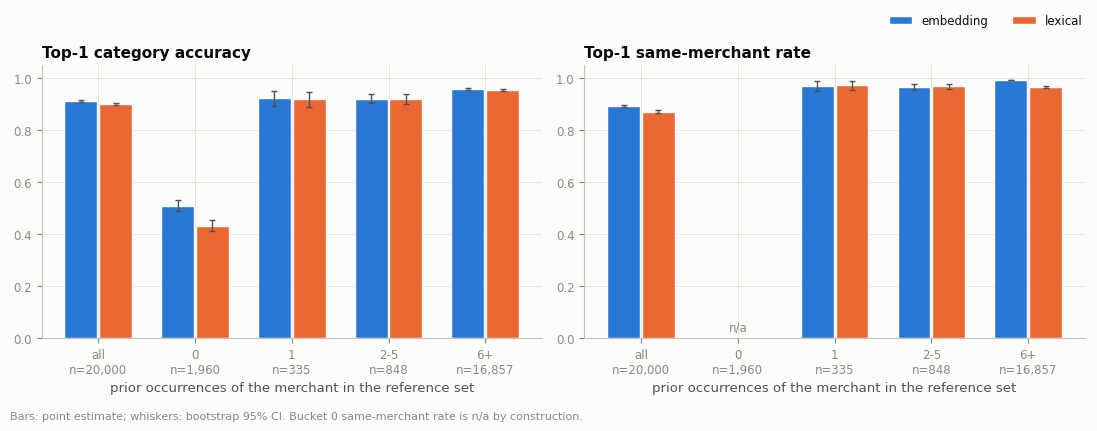

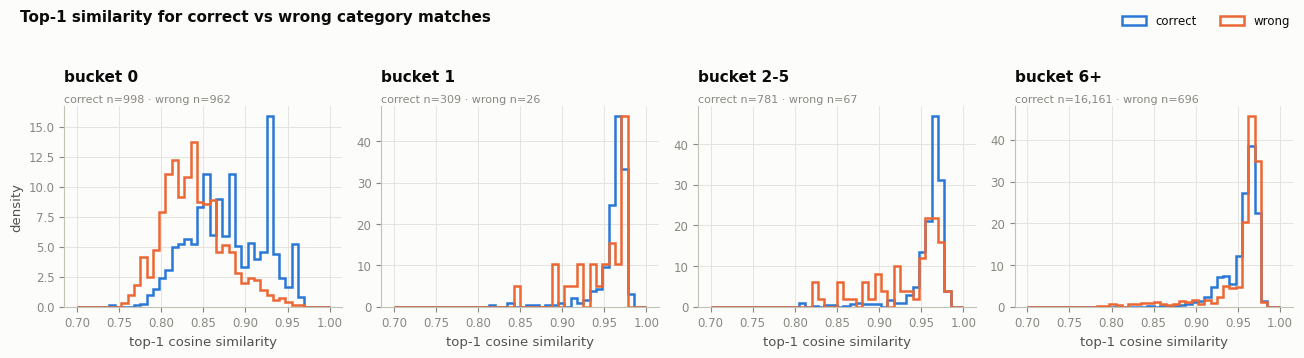

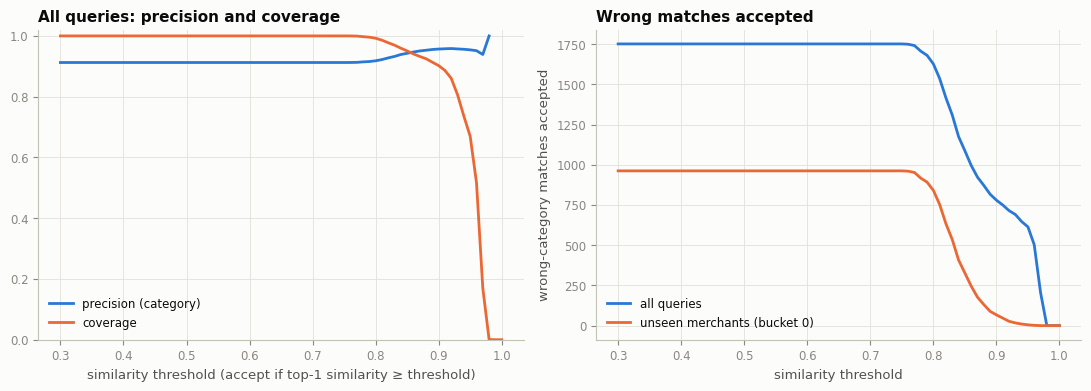

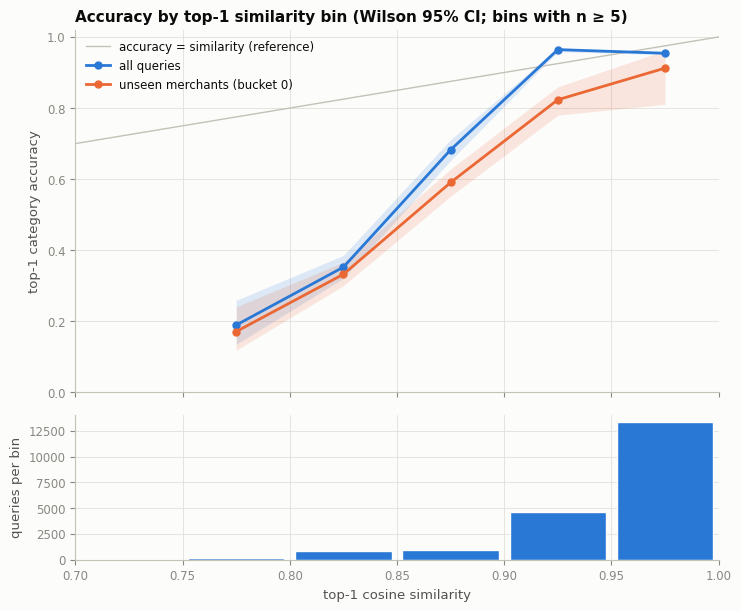

['accuracy_by_bucket.png', 'reliability.png', 'similarity_hist_correct_vs_wrong.png', 'threshold_curve.png']


In [22]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
C1, C2 = "#2a78d6", "#eb6834"      # categorical slots 1-2 (validated colour-blind-safe pair)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8.5, "font.size": 9.5,
})
FIG = f"{RESULTS_DIR}/figures"
sx = lambda b: "all" if b == "all" else f"{b}"
main = acc_df[(acc_df.key_def == "strict") & (acc_df.subset == "all")]

# 1. Accuracy by bucket, embedding vs lexical
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
xs = ["all"] + BUCKET_LABELS
x = np.arange(len(xs))
for ax, (metric, lo_c, hi_c, title) in zip(axes, [
        ("category_acc", "category_acc_ci_low", "category_acc_ci_high", "Top-1 category accuracy"),
        ("same_merchant_rate", "same_merchant_ci_low", "same_merchant_ci_high", "Top-1 same-merchant rate")]):
    for j, (method, color) in enumerate([("embedding", C1), ("lexical", C2)]):
        d = main[main.method == method].set_index("bucket").reindex(xs)
        v = d[metric].values
        err = np.vstack([v - d[lo_c].values, d[hi_c].values - v])
        ax.bar(x + (j - 0.5) * 0.36, np.nan_to_num(v), width=0.34, color=color, label=method,
               edgecolor=SURFACE, linewidth=1)
        ax.errorbar(x + (j - 0.5) * 0.36, v, yerr=err, fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
    ns = main[main.method == "embedding"].set_index("bucket").reindex(xs)["n"].values
    ax.set_xticks(x, [f"{sx(b)}\nn={n:,}" for b, n in zip(xs, ns)])
    ax.set_xlabel("prior occurrences of the merchant in the reference set")
    ax.set_ylim(0, 1.05)
    ax.set_title(title, loc="left")
    if metric == "same_merchant_rate":
        ax.text(x[1], 0.03, "n/a", ha="center", color=MUTED, fontsize=8.5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(0.995, 0.995))
fig.text(0.01, 0.005, "Bars: point estimate; whiskers: bootstrap 95% CI. Bucket 0 same-merchant rate is n/a by construction.",
         color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
fig.savefig(f"{FIG}/accuracy_by_bucket.png", dpi=150)
plt.show()

# 2. Similarity histograms, correct vs wrong, one panel per bucket
fig, axes = plt.subplots(1, len(BUCKET_LABELS), figsize=(13, 3.6), sharex=True)
bins = np.linspace(np.floor(res["sim_top1"].min() * 20) / 20, 1.0, 41)
for ax, b in zip(axes, BUCKET_LABELS):
    sub = res[res["bucket"] == b]
    ns = {}
    for outcome, mask, color in [("correct", sub["category_correct"], C1), ("wrong", ~sub["category_correct"], C2)]:
        vals = sub.loc[mask, "sim_top1"]
        ns[outcome] = len(vals)
        if len(vals):
            ax.hist(vals, bins=bins, density=True, histtype="step", linewidth=1.8, color=color, label=outcome)
    ax.set_title(f"bucket {b}", loc="left", y=1.08)
    ax.text(0.0, 1.01, f"correct n={ns['correct']:,} · wrong n={ns['wrong']:,}", transform=ax.transAxes,
            ha="left", va="bottom", color=MUTED, fontsize=8)
    ax.set_xlabel("top-1 cosine similarity")
axes[0].set_ylabel("density")
fig.legend(*axes[-1].get_legend_handles_labels(), loc="upper right", ncol=2, bbox_to_anchor=(0.995, 0.995))
fig.suptitle("Top-1 similarity for correct vs wrong category matches", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(f"{FIG}/similarity_hist_correct_vs_wrong.png", dpi=150)
plt.show()

# 3. Threshold sweep: precision & coverage (one 0-1 axis); wrong matches accepted (separate panel, no dual axis)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
a = sweep_df[sweep_df.scope == "all"]
axes[0].plot(a["threshold"], a["precision_category"], color=C1, linewidth=2, label="precision (category)")
axes[0].plot(a["threshold"], a["coverage"], color=C2, linewidth=2, label="coverage")
axes[0].set_ylim(0, 1.02)
axes[0].set_xlabel("similarity threshold (accept if top-1 similarity ≥ threshold)")
axes[0].set_title("All queries: precision and coverage", loc="left")
axes[0].legend(loc="best")
u = sweep_df[sweep_df.scope == "0"]
axes[1].plot(a["threshold"], a["n_wrong_category_accepted"], color=C1, linewidth=2, label="all queries")
axes[1].plot(u["threshold"], u["n_wrong_category_accepted"], color=C2, linewidth=2, label="unseen merchants (bucket 0)")
axes[1].set_xlabel("similarity threshold")
axes[1].set_ylabel("wrong-category matches accepted")
axes[1].set_title("Wrong matches accepted", loc="left")
axes[1].legend(loc="best")
fig.tight_layout()
fig.savefig(f"{FIG}/threshold_curve.png", dpi=150)
plt.show()

# 4. Reliability-style plot: accuracy per similarity bin (+ counts panel)
fig, (ax, axn) = plt.subplots(2, 1, figsize=(7.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, label="accuracy = similarity (reference)")
for scope, color, label in [("all", C1, "all queries"), ("0", C2, "unseen merchants (bucket 0)")]:
    d = rel_df[(rel_df.scope == scope) & (rel_df.n >= 5)]
    mid = (d["bin_low"] + d["bin_high"]) / 2
    ax.plot(mid, d["accuracy"], color=color, linewidth=2, marker="o", markersize=5, label=label)
    ax.fill_between(mid, d["ci_low"], d["ci_high"], color=color, alpha=0.15, linewidth=0)
ax.set_xlim(edges[0], 1.0)
ax.set_ylim(0, 1.02)
ax.set_ylabel("top-1 category accuracy")
ax.set_title("Accuracy by top-1 similarity bin (Wilson 95% CI; bins with n ≥ 5)", loc="left")
ax.legend(loc="best")
d_all = rel_df[rel_df.scope == "all"]
axn.bar((d_all["bin_low"] + d_all["bin_high"]) / 2, d_all["n"], width=W * 0.9, color=C1, edgecolor=SURFACE)
axn.set_ylabel("queries per bin")
axn.set_xlabel("top-1 cosine similarity")
fig.tight_layout()
fig.savefig(f"{FIG}/reliability.png", dpi=150)
plt.show()
print(sorted(os.listdir(FIG)))

## 13. `metrics.json` and README table snippets

In [23]:
CONFIG = {k: globals()[k] for k in [
    "MODEL_ID", "MODEL_REVISION", "DTYPE", "MAX_SEQ_LENGTH", "QUERY_PROMPT_NAME", "DOC_PROMPT_NAME",
    "RUN_PROMPT_ABLATION", "PROMPT_ABLATION", "ENC_BATCH", "SIM_CHUNK", "DATA_URL", "EXPECTED_DATA_SHA256",
    "COLUMN_MAP", "DATE_FORMAT", "DATA_START", "DATA_END", "EXCLUDE_CATEGORIES", "PROCESSOR_PREFIXES",
    "SPACE_PREFIXES", "KEY_STOPWORDS", "SPLIT_DATE", "SPLIT_QUANTILE", "N_QUERIES", "SEED", "BUCKETS", "N_BOOTSTRAP",
    "THRESHOLDS", "RELIABILITY_BIN_WIDTH", "N_LOOKALIKES", "N_FAILURES_PER_BUCKET", "N_NOISE", "TRUNC_LEN",
    "NOISE_PREFIXES", "LEX_ANALYZER", "LEX_NGRAM", "SMOKE_TEST", "SMOKE_MAX_REF"]}
METRICS = {
    "smoke_test": SMOKE_TEST,
    "config": CONFIG,
    "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "dtype": DTYPE, "n_parameters": N_PARAMS,
              "prompts": PROMPTS, "device": DEVICE},
    "environment": ENV,
    "data": {"source_page": DATA_SOURCE_PAGE, "url": DATA_URL, "license": DATA_LICENSE, "loaded_snapshot": IS_SNAPSHOT,
             "window": [DATA_START, DATA_END], "cleaning": CLEANING_LOG, "sha256": DATA_SHA256,
             "n_categories": int(df["category"].nunique()), "merchant_key_diagnostics": KEY_DIAGNOSTICS},
    "split": SPLIT_INFO,
    "metrics": {
        "majority_category": MAJORITY_CATEGORY,
        "accuracy_by_bucket": acc_df.to_dict("records"),
        "separability_auroc": SEPARABILITY,
        "similarity_stats": sim_df.to_dict("records"),
        "novelty_auroc": NOVELTY,
        "threshold_sweep_all_queries": sweep_df[sweep_df.scope == "all"].to_dict("records"),
        "noise_robustness": noise_df.to_dict("records"),
        "prompt_ablation": abl_df.to_dict("records"),
        "lexical_queries_without_ngram_overlap": int((~res["lex_has_overlap"]).sum()),
        "share_exact_string_in_reference": float(res["exact_string_in_reference"].mean()),
    },
    "timings_sec": TIMINGS,
}
with open(f"{RESULTS_DIR}/metrics.json", "w") as f:
    json.dump(to_jsonable(METRICS), f, indent=2)
print("wrote", f"{RESULTS_DIR}/metrics.json")

wrote results/metrics.json


In [24]:
# README snippets: upload_to_hf_bucket.py pastes these between the <!-- AUTO:... --> markers in README.md.
AUTO = f"{RESULTS_DIR}/readme_auto"
smoke_note = "> **SMOKE TEST OUTPUT: pipeline check only, not results.**\n\n" if SMOKE_TEST else ""

# dataset
c = CLEANING_LOG
dataset_md = smoke_note + md_table(pd.DataFrame([
    ["Source", f"[State of Delaware: State Employee Credit Card Transactions]({DATA_SOURCE_PAGE})"],
    ["Licence", DATA_LICENSE],
    ["Window", f"{DATA_START} to {DATA_END}"],
    ["Rows after cleaning", f"{c['final_rows']:,}"],
    ["Distinct descriptors", f"{KEY_DIAGNOSTICS['n_distinct_descriptors']:,}"],
    ["Categories (normalised)", f"{df['category'].nunique():,}"],
    ["Merchant keys (strict / loose)", f"{KEY_DIAGNOSTICS['n_strict_keys']:,} / {KEY_DIAGNOSTICS['n_loose_keys']:,}"],
    ["Category majority share per strict key / per descriptor",
     f"{KEY_DIAGNOSTICS['category_majority_share_per_strict_key']:.3f} / {KEY_DIAGNOSTICS['category_majority_share_per_descriptor']:.3f}"],
    ["Split date", f"{SPLIT_INFO['split_date']} ({'computed at quantile ' + str(SPLIT_QUANTILE) if SPLIT_COMPUTED else 'fixed'})"],
    ["Reference transactions / unique descriptors",
     f"{SPLIT_INFO['n_reference_transactions']:,} / {SPLIT_INFO['n_reference_descriptors']:,}"],
    ["Query pool / sampled queries", f"{SPLIT_INFO['n_query_pool']:,} / {SPLIT_INFO['n_queries']:,} (seed {SEED})"],
    ["Queries per bucket 0 / 1 / 2-5 / 6+ (strict)", " / ".join(f"{bucket_counts[b]:,}" for b in BUCKET_LABELS)],
    ["Queries whose exact descriptor is in the reference set", f"{res['exact_string_in_reference'].mean():.3f}"],
    ["Content SHA-256 (data/transactions_window.csv.gz, uncompressed)", f"`{DATA_SHA256}`"],
], columns=["Item", "Value"]))

def acc_table(frame):
    out = []
    for b in ["all"] + BUCKET_LABELS:
        e = frame[(frame.method == "embedding") & (frame.bucket == b)].iloc[0]
        l = frame[(frame.method == "lexical") & (frame.bucket == b)].iloc[0]
        mj = frame[(frame.method == "majority_category") & (frame.bucket == b)].iloc[0]
        out.append([b, f"{int(e.n):,}",
                    fmt_ci(e.category_acc, e.category_acc_ci_low, e.category_acc_ci_high),
                    fmt_ci(l.category_acc, l.category_acc_ci_low, l.category_acc_ci_high),
                    fmt(mj.category_acc),
                    fmt_ci(e.same_merchant_rate, e.same_merchant_ci_low, e.same_merchant_ci_high),
                    fmt_ci(l.same_merchant_rate, l.same_merchant_ci_low, l.same_merchant_ci_high)])
    return md_table(pd.DataFrame(out, columns=["Prior occurrences", "n", "Embedding category acc [95% CI]",
                                               "Lexical category acc [95% CI]", "Majority-category acc",
                                               "Embedding same-merchant [95% CI]", "Lexical same-merchant [95% CI]"]))

sel = lambda kd, sub: acc_df[(acc_df.key_def == kd) & (acc_df.subset == sub)]
sep_tbl = pd.DataFrame([[b,
    f"{int(sim_df[(sim_df.bucket == b) & (sim_df.outcome == 'correct')].n.iloc[0]):,}",
    fmt(sim_df[(sim_df.bucket == b) & (sim_df.outcome == 'correct')]['mean'].iloc[0]),
    f"{int(sim_df[(sim_df.bucket == b) & (sim_df.outcome == 'wrong')].n.iloc[0]):,}",
    fmt(sim_df[(sim_df.bucket == b) & (sim_df.outcome == 'wrong')]['mean'].iloc[0]),
    fmt_ci(SEPARABILITY[b]['auroc_sim_predicts_category_correct'], SEPARABILITY[b]['ci_low'], SEPARABILITY[b]['ci_high'])]
    for b in ["all"] + BUCKET_LABELS],
    columns=["Prior occurrences", "n correct", "mean sim (correct)", "n wrong", "mean sim (wrong)",
             "AUROC: similarity separates correct from wrong [95% CI]"])
nov_tbl = pd.DataFrame([[v["method"], v["key_def"], f"{v['n_unseen']:,} / {v['n_seen']:,}",
                         fmt_ci(v["auroc"], v["ci_low"], v["ci_high"])] for v in NOVELTY.values()],
                       columns=["Method", "Merchant key", "unseen / seen queries", "AUROC (−top-1 similarity) [95% CI]"])
thr = sweep_df[sweep_df.threshold.isin(README_THRESHOLDS)]
thr_tbl = pd.DataFrame([[f"{t:.2f}",
    fmt(thr[(thr.scope == 'all') & (thr.threshold == t)].coverage.iloc[0]),
    fmt(thr[(thr.scope == 'all') & (thr.threshold == t)].precision_category.iloc[0]),
    f"{int(thr[(thr.scope == 'all') & (thr.threshold == t)].n_wrong_category_accepted.iloc[0]):,}",
    f"{int(thr[(thr.scope == '0') & (thr.threshold == t)].n_wrong_category_accepted.iloc[0]):,}"]
    for t in README_THRESHOLDS],
    columns=["Threshold", "Coverage", "Precision (category)", "Wrong accepted (all)", "Wrong accepted (bucket 0)"])
noise_tbl = pd.DataFrame([[cond,
    fmt_ci(*noise_df[(noise_df.condition == cond) & (noise_df.method == 'embedding')][["same_merchant_at1", "same_merchant_ci_low", "same_merchant_ci_high"]].iloc[0]),
    fmt_ci(*noise_df[(noise_df.condition == cond) & (noise_df.method == 'lexical')][["same_merchant_at1", "same_merchant_ci_low", "same_merchant_ci_high"]].iloc[0]),
    fmt(noise_df[(noise_df.condition == cond) & (noise_df.method == 'embedding')].exact_original_at1.iloc[0]),
    fmt(noise_df[(noise_df.condition == cond) & (noise_df.method == 'lexical')].exact_original_at1.iloc[0]),
    fmt(noise_df[(noise_df.condition == cond) & (noise_df.method == 'embedding')].mean_cos_to_original.iloc[0])]
    for cond in CONDITIONS],
    columns=["Condition", "Embedding same-merchant@1 [95% CI]", "Lexical same-merchant@1 [95% CI]",
             "Embedding exact-original@1", "Lexical exact-original@1", "Embedding mean cos to original"])
abl_tbl = (abl_df.assign(acc=lambda d: [fmt_ci(a, l, h) for a, l, h in zip(d.category_acc, d.category_acc_ci_low, d.category_acc_ci_high)])
                 .pivot(index="config", columns="bucket", values="acc")[["all"] + BUCKET_LABELS].reset_index())
abl_tbl["novelty AUROC"] = abl_tbl["config"].map(abl_df.drop_duplicates("config").set_index("config")
                                                 .apply(lambda r: fmt_ci(r.novelty_auroc, r.novelty_auroc_ci_low, r.novelty_auroc_ci_high), axis=1))

results_md = smoke_note + "\n\n".join([
    "**Table 1: Top-1 accuracy by prior occurrences of the merchant (strict merchant key, all queries).**", acc_table(sel("strict", "all")),
    "**Table 2: Same as Table 1, restricted to queries whose exact descriptor string is NOT in the reference set.**", acc_table(sel("strict", "new_string")),
    "**Table 3: Same as Table 1, restricted to queries whose exact descriptor string IS in the reference set.**", acc_table(sel("strict", "exact_string_in_reference")),
    "**Table 4: Sensitivity: Table 1 under the loose merchant key (first token of the strict key).**", acc_table(sel("loose", "all")),
    "**Table 5: Top-1 similarity of correct vs wrong category matches (embedding).**", md_table(sep_tbl),
    "**Table 6: Novelty detection: (−top-1 similarity) as a score for unseen merchants.**", md_table(nov_tbl),
    "**Table 7: Trust-threshold sweep (embedding; full sweep in `results/threshold_sweep.csv`).**", md_table(thr_tbl),
    f"**Table 8: Noise robustness (n = {len(orig_idx):,} reference descriptors longer than {TRUNC_LEN} chars).**", md_table(noise_tbl),
    "**Table 9: Task-prompt comparison: embedding top-1 category accuracy [95% CI] by bucket.**", md_table(abl_tbl),
    "**Figures**",
    "![Accuracy by bucket](results/figures/accuracy_by_bucket.png)",
    "![Similarity correct vs wrong](results/figures/similarity_hist_correct_vs_wrong.png)",
    "![Threshold curve](results/figures/threshold_curve.png)",
    "![Reliability](results/figures/reliability.png)",
])

fail_show = lambda d: md_table(d.assign(sim_top1=d.sim_top1.map(lambda v: f"{v:.3f}"))[
    ["bucket", "query_descriptor", "matched_descriptor", "sim_top1", "query_category", "matched_category"]])
failures_md = smoke_note + "\n\n".join([
    "**Highest-similarity wrong-category matches, top 3 per bucket (full list: `results/example_failures.csv`).**",
    fail_show(failures.groupby("bucket", observed=True).head(3)),
    "**Highest-similarity matches to a different merchant key, top 10 (full list: `results/lookalikes.csv`).**",
    md_table(lookalikes.head(10).assign(sim_top1=lambda d: d.sim_top1.map(lambda v: f"{v:.3f}"))[
        ["bucket", "query_descriptor", "matched_descriptor", "sim_top1", "same_merchant_loose", "category_correct"]]),
])

environment_md = smoke_note + md_table(pd.DataFrame(
    [["Model", f"`{MODEL_ID}` @ `{MODEL_REVISION[:12]}`"], ["Parameters (loaded checkpoint)", f"{N_PARAMS:,}"],
     ["dtype / device", f"{DTYPE} / {DEVICE}" + (f" ({ENV['gpu']})" if ENV["gpu"] else "")],
     ["Prompts", "; ".join(f"`{k}` = `{v}`" for k, v in PROMPTS.items())],
     ["Packages", ", ".join(f"{p} {ENV[p]}" for p in ["torch", "transformers", "sentence-transformers", "huggingface_hub", "scikit-learn", "pandas", "numpy"])],
     ["Python", ENV["python"]], ["Seed", str(SEED)],
     ["Wall-clock per stage (s)", ", ".join(f"{k} {v}" for k, v in TIMINGS.items())]],
    columns=["Item", "Value"]))

for name, text in [("dataset", dataset_md), ("results", results_md), ("failures", failures_md), ("environment", environment_md)]:
    with open(f"{AUTO}/{name}.md", "w") as f:
        f.write(text + "\n")
print("wrote README snippets:", sorted(os.listdir(AUTO)))

wrote README snippets: ['dataset.md', 'environment.md', 'failures.md', 'results.md']


## 14. Package artifacts
This zips `results/` and `data/` (raw download and embedding caches are excluded). In Colab the zip downloads
automatically. Then:
1. Unzip it into the project folder next to `README.md` and `upload_to_hf_bucket.py`.
2. Save this executed notebook there too (*File → Download → Download .ipynb*).
3. Write your own README sections, then run `python upload_to_hf_bucket.py --bucket <owner>/<name>`.

In [ ]:
zip_path = f"artifacts_{RESULTS_DIR}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (RESULTS_DIR, DATA_OUT_DIR):
        for root, _, files in os.walk(folder):
            for fn in sorted(files):
                z.write(os.path.join(root, fn))
print(f"{zip_path}: {os.path.getsize(zip_path) / 1e6:.1f} MB")
try:
    from google.colab import files  # noqa: F401
    files.download(zip_path)
except ImportError:
    print("Not running in Colab: the zip is at", os.path.abspath(zip_path))